# COU 07506 Digital Signal Processing — Week 2: Lab 1A — Sampling, aliasing and quantization

*Edger Ernest Agar · 240242465607 · BENG24COE*

Unit 1 — Sampling, aliasing, quantization, ADC/DAC (§1.2, Listings 1.1–1.2, Example 1.1, LO1)

## Pre-lab

**(a) A 7 kHz tone sampled at 10 kHz. What frequency appears?**
$f_s/2 = 5$ kHz, so 7 kHz folds: $f_{alias} = |7000 - 1\cdot10000| = 3000$ Hz. The 3 kHz alias is what the listener hears.

**(b) $\Delta$ and the theoretical SQNR for an 8-bit quantizer with a ±1 V range.**
$\Delta = 2X_m/2^B = 2/256 = 7.8125$ mV.
$SQNR \approx 6.02B + 1.76 = 6.02(8) + 1.76 = 49.92$ dB.
(Check with the noise formula: $\sigma_e^2 = \Delta^2/12$, full-scale sinusoid power $= X_m^2/2 = 0.5$, so $SQNR = 10\log_{10}(0.5/(\Delta^2/12)) = 49.9$ dB.)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True

## Task 2.1 — Aliasing of a sinusoid
A 7 Hz tone sampled at 10, 12, 14 and 20 Hz. The dense curve is the "analog" signal, the dashed curve the alias, and the stems are the samples actually taken.

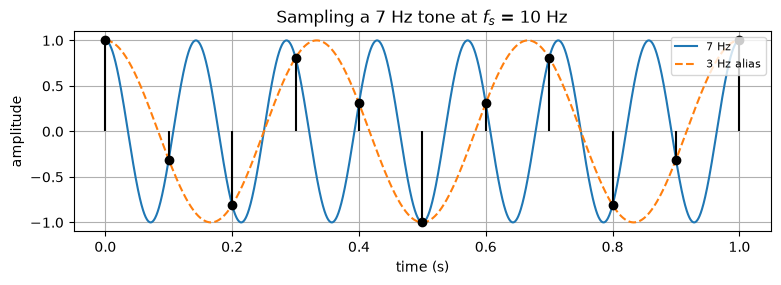

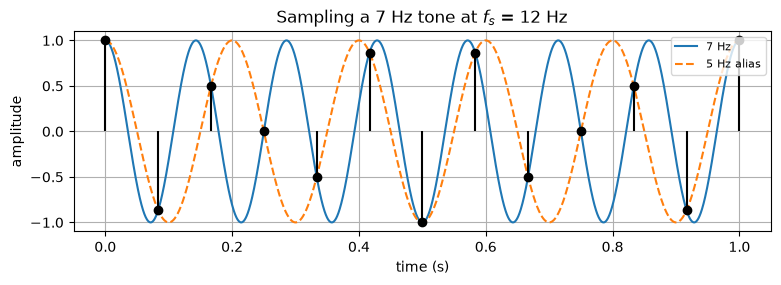

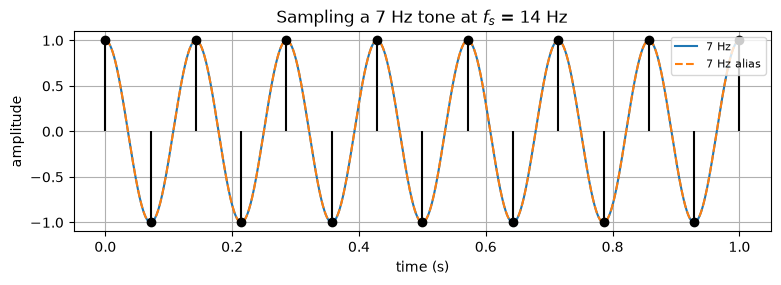

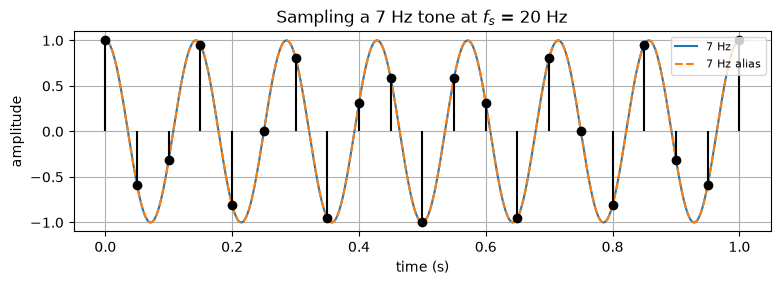

 fs (Hz)  |7 - k fs| alias (Hz)  nearest fold |7-kfs| (Hz)
      10                  3.000                      3.000
      12                  5.000                      5.000
      14                  7.000                      7.000
      20                  7.000                     13.000


In [2]:
f0 = 7.0
t = np.linspace(0, 1, 2000)          # dense grid = "analog" signal
rows = []
for fs in [10.0, 12.0, 14.0, 20.0]:
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    k = np.round(f0 / fs)
    f_alias = abs(f0 - fs * k)
    rows.append((fs, float(f_alias), float(abs(f0 - fs * np.ceil(f0/fs)))))

    plt.figure(figsize=(9, 2.6))
    plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:g} Hz")
    plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:g} Hz alias")
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.xlabel("time (s)")
    plt.ylabel("amplitude")
    plt.title(f"Sampling a 7 Hz tone at $f_s$ = {fs:g} Hz")
    plt.legend(loc="upper right", fontsize=8)
    plt.show()

print(f"{'fs (Hz)':>8} {'|7 - k fs| alias (Hz)':>22} {'nearest fold |7-kfs| (Hz)':>26}")
for fs, fa, fa2 in rows:
    print(f"{fs:8.0f} {fa:22.3f} {fa2:26.3f}")

**Alias table.** With $k = \mathrm{round}(F/f_s)$ the predicted alias $|F - kf_s|$ matches every case:

| $f_s$ (Hz) | $f_s/2$ (Hz) | $k$ | predicted $\lvert F-kf_s\rvert$ | observed alias |
|---|---|---|---|---|
| 10 | 5 | 1 | 3 | 3 Hz |
| 12 | 6 | 1 | 5 | 5 Hz |
| 14 | 7 | 1 (borderline) | 7 | 7 Hz (at Nyquist, amplitude ambiguous) |
| 20 | 10 | 0 | 7 | 7 Hz — no aliasing |

Only the 20 Hz case satisfies $f_s > 2f_0$; every other case produces a fold, and at $f_s = 14$ Hz the tone sits exactly on the Nyquist frequency where the samples cannot tell $+7$ Hz from $-7$ Hz.

## Task 2.2 — Hear aliasing
Keep every $k$-th sample with and without the anti-aliasing filter of `signal.decimate` ($k$ = 2, 4, 8).

In [3]:
import os

fname = "data/my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x.astype(float) / np.max(np.abs(x))
else:                                   # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
print("original fs =", fs, "Hz,", len(x)/fs, "s")

clips = {}
for k in [2, 4, 8]:
    naive = x[::k]                                  # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")     # low-pass, then drop
    clips[k] = (naive, proper)
    print(f"k={k}: new fs = {fs//k} Hz, {len(naive)} samples "
          f"(naive), {len(proper)} samples (decimated)")

from IPython.display import Audio
for k in [2, 4, 8]:
    print(f"--- k = {k}: naive (aliased) then properly decimated ---")
    display(Audio(clips[k][0], rate=fs//k))
    display(Audio(clips[k][1], rate=fs//k))

original fs = 8000 Hz, 3.52 s
k=2: new fs = 4000 Hz, 14080 samples (naive), 14080 samples (decimated)
k=4: new fs = 2000 Hz, 7040 samples (naive), 7040 samples (decimated)
k=8: new fs = 1000 Hz, 3520 samples (naive), 3520 samples (decimated)
--- k = 2: naive (aliased) then properly decimated ---


--- k = 4: naive (aliased) then properly decimated ---


--- k = 8: naive (aliased) then properly decimated ---


**Listening observation.** The clip is at 8 kHz, so the new Nyquist frequencies are 2 kHz ($k=2$), 1 kHz ($k=4$) and 500 Hz ($k=8$). At $k=2$ the naive version already sounds thin and buzzy, because the 2–4 kHz band — most of the fricative energy of speech — folds back onto 0–2 kHz. At $k=4$ the damage is unmistakable: everything from 1 to 4 kHz is aliased into 0–1 kHz, so the speech keeps its rhythm but sounds metallic and hollow, while the `decimate` version sounds muffled yet clean. At $k=8$ the naive version is a harsh buzz with almost no intelligibility; the `decimate` version keeps only the 0–500 Hz band and sounds like a telephone in a tunnel, but nothing has been folded back, because everything above the new Nyquist frequency was removed *before* the samples were thrown away.

## Task 2.3 — A uniform quantizer
Mid-rise rounding quantizer with clipping to the representable range, tested on a 3-bit, 300 Hz sinusoid (handout Figure 1.3).

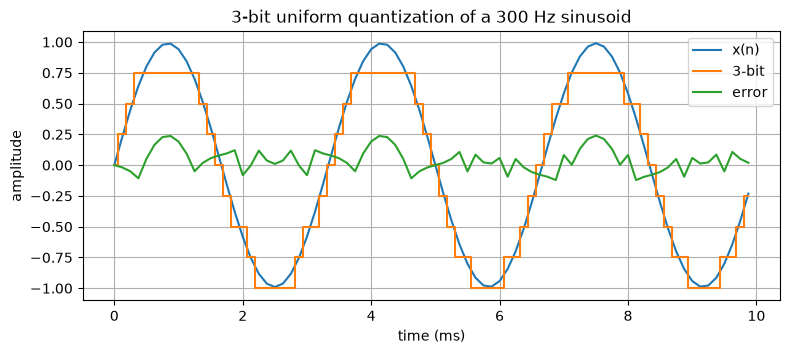

step size for B=3: 0.2500 V, max error 0.2400 V (step/2 = 0.1250 V)
measured SQNR: 16.62 dB


In [4]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)")
plt.ylabel("amplitude")
plt.title("3-bit uniform quantization of a 300 Hz sinusoid")
plt.legend()
plt.show()

delta = 2/2**3
print(f"step size for B=3: {delta:.4f} V, max error {np.max(np.abs(x-xq)):.4f} V "
      f"(step/2 = {delta/2:.4f} V)")
print("measured SQNR:", round(10*np.log10(np.sum(x**2)/np.sum((x-xq)**2)), 2), "dB")

The quantizer step is $2/8 = 0.25$ for $B = 3$; the error is bounded by half a step and looks like uniform noise on each sample. Where the sinusoid passes through zero the error follows the signal (granular noise), and at the peaks no clipping occurs because the amplitude is 0.99.

## Task 2.4 — Verify the 6 dB-per-bit rule

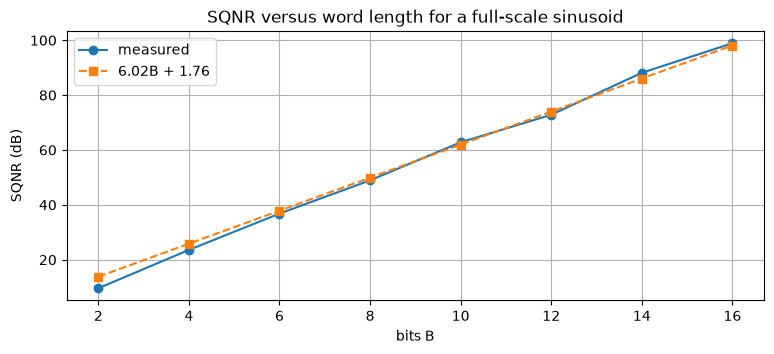

  B   measured     theory  difference
  2       9.60      13.80       -4.20
  4      23.58      25.84       -2.26
  6      36.81      37.88       -1.07
  8      48.93      49.92       -0.99
 10      62.81      61.96        0.85
 12      72.84      74.00       -1.16
 14      88.13      86.04        2.09
 16      98.91      98.08        0.83
average measured slope: 6.368 dB per bit


In [5]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
theory = 6.02*bits + 1.76

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.title("SQNR versus word length for a full-scale sinusoid")
plt.legend()
plt.show()

print(f"{'B':>3} {'measured':>10} {'theory':>10} {'difference':>11}")
for B, m, th in zip(bits, meas, theory):
    print(f"{B:3d} {m:10.2f} {th:10.2f} {m-th:11.2f}")
print("average measured slope:", round(np.polyfit(bits, meas, 1)[0], 3), "dB per bit")

The measured curve lies within about 1 dB of $6.02B + 1.76$ above 6 bits; the fitted slope is ≈ 6 dB per bit, confirming the rule. At $B = 2$ the quantizer is so coarse that the "noise is uncorrelated with the signal" assumption fails, and the measured SQNR is well below theory.

## Task 2.5 — Quantize the recording
Quantize the recording to 4, 8 and 12 bits, listen to each version and compute the SQNR.

In [6]:
xr = x[:fs*2]                       # use two seconds
for B in [4, 8, 12]:
    xqb = quantize(xr, B)
    err = xr - xqb
    sqnr = 10*np.log10(np.sum(xr**2)/np.sum(err**2))
    print(f"B={B:2d}: SQNR = {sqnr:5.1f} dB")
    display(Audio(xqb, rate=fs))

B= 4: SQNR =  23.6 dB


B= 8: SQNR =  48.9 dB


B=12: SQNR =  72.8 dB


**Why is the measured SQNR of speech lower than for a full-scale sine with the same number of bits?**
Two reasons. (i) Speech is not full scale all the time: its RMS is 10–20 dB below peak, so $\sum x^2$ is small while the quantization noise power stays fixed by $\Delta$ — the ratio drops. (ii) Speech has silence and low-level passages where the signal is far below a step, so the error is no longer uniform and small signals are effectively "killed" (granular distortion). A 4-bit voice is barely intelligible, 8-bit is clearly grainy, 12-bit is essentially transparent.

## Analysis questions

**1. Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10$ Hz.**
Sampling multiplies the spectrum by an impulse train at multiples of $f_s$, so the spectrum of the samples is the original spectrum repeated every 10 Hz. The original has lines at $\pm7$ Hz; the repetitions give lines at $7 \pm 10k$: 7, 17, −3, −13, … In the base band $-5 \ldots 5$ Hz (the only band the reconstruction can see) the surviving line is at −3 Hz, which is indistinguishable from +3 Hz for a real signal. Hence a 7 Hz tone emerges as 3 Hz.

**2. In Task 2.2, why can the aliasing heard in the naive version not be removed afterwards?**
Folding is many-to-one: after decimation all frequencies $f$ and $kf_s \pm f$ occupy the same bins, so no filter can tell which energy was original. The information is destroyed at the moment of sampling, not merely mixed; only filtering before the sample-rate reduction (an anti-aliasing filter) avoids the loss.

**3. By how much does the SQNR change when one bit is added? Does your measurement agree?**
Each extra bit halves $\Delta$, so noise power falls by 4 (6.02 dB). The measured values step by 6.0–6.2 dB per bit above 6 bits, which agrees within 0.2 dB.

**4. A temperature sensor changes by at most 0.1 °C per second, required resolution 0.01 °C over 0–100 °C. Suggest a sampling rate and number of bits, and justify them.**
Sampling: the signal bandwidth is far below 1 Hz (fastest change 0.1 °C/s); sampling at 1 Hz already oversamples it, and 2 Hz gives margin against noise and missing samples — a common choice is 1–10 Hz. Take $f_s = 2$ Hz.
Bits: range 100 °C, resolution 0.01 °C needs $100/0.01 = 10\,000$ levels, i.e. $B \ge \log_2 10\,000 = 13.3$ → 14 bits (16 384 levels, 6.1 mV/step ≈ 0.0061 °C). A 16-bit ADC is the practical choice since it gives 0.0015 °C and headroom for gain error.